# Ratio redondant / divergent sur les K majoritaires

Pour chacun des trois cas du protocole de De Santiago et al. 2024 (**K fixé**, **Q fixé**, **sélection conjointe**) et chaque jeu (Familles, Ka et Ks) :

1. On lit le CSV de sélection **déjà sauvegardé** (`simulation_selection_K_Q.csv`) : **aucune simulation n'est relancée**. On en tire le **K majoritaire** (valeur la plus souvent sélectionnée sur les réplicats) et le Q associé.
2. Ce CSV ne contient que les K et Q sélectionnés, pas les affectations des paires aux clusters. Il faut donc **un seul ajustement de `MimiSBM` par couple (K, Q) majoritaire** sur le tenseur observé, ce qui est très court comparé à la grille complète. Les affectations sont sauvegardées dans un CSV et réutilisées aux exécutions suivantes.
3. On croise ces clusters avec les labels de `Y_train_clean` pour obtenir le ratio redondant / divergent par cluster.

## Configuration

In [3]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

repo_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "mimisbm_main" / "mimisbm" / "_base.py").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Introuvable : mimisbm_main/mimisbm/_base.py")
sys.path.insert(0, str(repo_root))
from mimisbm_main.mimisbm._base import MimiSBM

# ---- Résultats déjà sauvegardés (dataset de ce notebook) ----
SELECTION_CSV = Path("../Plots/mimiSBM/simulation_model_selection") / "selections_50_simulations.csv"
# True  : CSV issu des grilles sur tenseurs dont les vues sont dupliquées jusqu'à V = 10
# False : CSV simulation_selection_K_Q_donnees_obs_v3.csv (tenseurs non dupliqués)
DUPLIQUER_VUES = True
V_CIBLE = 10

# ---- Tenseurs observés (nécessaires pour récupérer les affectations aux K majoritaires) ----
FAMILY_DIR = repo_root.parent / "Données" / "adjacency" / "lda" / "family"
PATHS_JEUX = {
    "Familles": {
        "Ka": FAMILY_DIR / "adjacency_matrix_silh_Ka.csv",
        "Ks": FAMILY_DIR / "adjacency_matrix_silh_Ks.csv",
        "Distance": FAMILY_DIR / "adjacency_matrix_silh_Distance.csv",
        "Ka_Ks": FAMILY_DIR / "adjacency_matrix_silh_Ka_Ks.csv",
    },
    "Ka et Ks": {
        "Ka": FAMILY_DIR / "adjacency_matrix_silh_Ka.csv",
        "Ks": FAMILY_DIR / "adjacency_matrix_silh_Ks.csv",
    },
}

# ---- Labels redondant / divergent ----
Y_PATH = repo_root.parent / "Données" / "Y_train_clean.csv"
ID_COL = None                 # colonne d'identifiant de paire ; None = même ordre que les matrices
LABEL_COL = "Classification"
VAL_REDONDANT = 0
VAL_DIVERGENT = 1

# ---- Ajustement unique par (K, Q) majoritaire ----
N_INIT, PRIORS, MAX_ITER, TOL, SEED = 10, "jeffreys", 100, 1e-6, 0

CRITERE_FIGURE = "ICL_approx"
OUTPUT_DIR = Path("ratio_redondant_divergent")
OUTPUT_DIR.mkdir(exist_ok=True)

## 1. K majoritaires à partir du CSV de sélection

In [5]:
NOMS_CAS = {
    # simulation_selection_K_Q.csv
    "Q avec K vrai": "K fixé",
    "K avec Q vrai": "Q fixé",
    "Sélection conjointe": "Sélection conjointe",
    # simulation_selection_K_Q_donnees_obs_v3.csv
    "K fixé, sélection de Q": "K fixé",
    "Q fixé, sélection de K": "Q fixé",
    "K et Q optimisés": "Sélection conjointe",
}
ORDRE_CAS = ["K fixé", "Q fixé", "Sélection conjointe"]
CRITERES = ["ILVB", "ICL_variationnel", "ICL_approx"]

sel = pd.read_csv(SELECTION_CSV)
sel["cas"] = sel["strategie"].map(NOMS_CAS)
inconnues = sel.loc[sel["cas"].isna(), "strategie"].unique()
if len(inconnues):
    raise ValueError(f"Stratégies non reconnues : {list(inconnues)}")


def majoritaire(g):
    """K le plus fréquent, puis Q le plus fréquent parmi les réplicats ayant choisi ce K."""
    comptes_k = g["K_selectionne"].value_counts()
    k_maj = int(comptes_k.index[comptes_k.to_numpy() == comptes_k.max()].min())
    sous = g[g["K_selectionne"] == k_maj]
    comptes_q = sous["Q_selectionne"].value_counts()
    q_maj = int(comptes_q.index[comptes_q.to_numpy() == comptes_q.max()].min())
    return {
        "K_majoritaire": k_maj,
        "Q_associe": q_maj,
        "freq_K": len(sous),
        "n_simulations": len(g),
        "ex_aequo": int((comptes_k == comptes_k.max()).sum()) > 1,
        "K_vrai": int(g["K_vrai"].iloc[0]),
        "Q_vrai": int(g["Q_vrai"].iloc[0]),
    }


majo = pd.DataFrame([
    {"jeu": jeu, "cas": cas, "critere": crit, **majoritaire(g)}
    for (jeu, cas, crit), g in sel.groupby(["jeu", "cas", "critere"])
])
majo["cas"] = pd.Categorical(majo["cas"], ORDRE_CAS, ordered=True)
majo["critere"] = pd.Categorical(majo["critere"], CRITERES, ordered=True)
majo = majo.sort_values(["jeu", "cas", "critere"]).reset_index(drop=True)
majo.to_csv(OUTPUT_DIR / "k_majoritaires.csv", index=False)
display(majo)

,jeu,cas,critere,K_majoritaire,Q_associe,freq_K,n_simulations,ex_aequo,K_vrai,Q_vrai
0,Familles,K fixé,ILVB,10,4,50,50,False,10,3
1,Familles,K fixé,ICL_variationnel,10,4,50,50,False,10,3
2,Familles,K fixé,ICL_approx,10,2,50,50,False,10,3
3,Familles,Q fixé,ILVB,10,3,23,50,False,10,3
4,Familles,Q fixé,ICL_variationnel,10,3,23,50,False,10,3
5,Familles,Q fixé,ICL_approx,10,3,23,50,False,10,3
6,Familles,Sélection conjointe,ILVB,10,4,33,50,False,10,3
7,Familles,Sélection conjointe,ICL_variationnel,10,4,33,50,False,10,3
8,Familles,Sélection conjointe,ICL_approx,10,2,31,50,False,10,3
9,Ka et Ks,K fixé,ILVB,6,2,50,50,False,6,2


## 2. Affectations des paires aux K majoritaires

Un ajustement `MimiSBM` (meilleur ELBO sur `N_INIT` initialisations) par couple (jeu, K, Q) distinct. Résultat mis en cache dans `affectations_K_majoritaires.csv`.

In [6]:
def charger_tenseur(paths):
    """Tenseur N×N×V et identifiants des paires (index des CSV)."""
    matrices, ids = {}, None
    for nom, chemin in paths.items():
        df = pd.read_csv(chemin, index_col=0)
        m = df.to_numpy()
        if m.shape[0] != m.shape[1]:
            raise ValueError(f"{nom}: matrice non carrée {m.shape}")
        if not np.all(np.isin(np.unique(m), [0, 1])):
            raise ValueError(f"{nom}: valeurs hors de {{0, 1}}")
        m = m.astype(np.int64)
        np.fill_diagonal(m, 0)
        matrices[nom] = np.maximum(m, m.T)
        ids = df.index.astype(str) if ids is None else ids
    noms = list(matrices)
    return np.stack([matrices[n] for n in noms], axis=2), noms, ids


def ajuster(tenseur, k, q):
    meilleur, meilleur_elbo = None, -np.inf
    for init in range(N_INIT):
        modele = MimiSBM(
            n_clusters=k, n_components=q,
            clusters_prior=PRIORS, components_prior=PRIORS, adjacency_prior=PRIORS,
            max_iter=MAX_ITER, tol=TOL, random_state=SEED + init,
        )
        try:
            modele.fit(tenseur)
        except ValueError as exc:
            if "Probabilities contain NaN" in str(exc):
                continue
            raise
        if np.isfinite(modele.elbo_) and modele.elbo_ > meilleur_elbo:
            meilleur, meilleur_elbo = modele, float(modele.elbo_)
    if meilleur is None:
        raise RuntimeError(f"Aucun ajustement valide pour K={k}, Q={q}")
    return meilleur


AFFECT_CSV = OUTPUT_DIR / "affectations_K_majoritaires.csv"
cache = pd.read_csv(AFFECT_CSV, dtype={"pair_id": str}) if AFFECT_CSV.exists() else pd.DataFrame(
    columns=["jeu", "K", "Q", "pair_id", "cluster"])

tenseurs, nouvelles = {}, []
for jeu, k, q in majo[["jeu", "K_majoritaire", "Q_associe"]].drop_duplicates().itertuples(index=False):
    deja = ((cache["jeu"] == jeu) & (cache["K"] == k) & (cache["Q"] == q)).any()
    if deja:
        continue
    if jeu not in tenseurs:
        A, vues, ids = charger_tenseur(PATHS_JEUX[jeu])
        if DUPLIQUER_VUES:
            A = A[:, :, np.arange(V_CIBLE) % A.shape[2]]
        tenseurs[jeu] = (A, ids)
    A, ids = tenseurs[jeu]
    modele = ajuster(A, k, q)
    print(f"{jeu} : K={k}, Q={q} ajusté (ELBO = {modele.elbo_:.1f})")
    nouvelles.append(pd.DataFrame({
        "jeu": jeu, "K": k, "Q": q, "pair_id": ids,
        "cluster": modele.cluster_responsibilities_.argmax(axis=1) + 1,
    }))

if nouvelles:
    cache = pd.concat([cache, *nouvelles], ignore_index=True)
    cache.to_csv(AFFECT_CSV, index=False)
print(f"{cache[['jeu', 'K', 'Q']].drop_duplicates().shape[0]} couples (jeu, K, Q) disponibles dans le cache")

Familles : K=10, Q=2 ajusté (ELBO = -279057.9)
Familles : K=10, Q=3 ajusté (ELBO = -151642.7)
6 couples (jeu, K, Q) disponibles dans le cache


## 3. Labels redondant / divergent

In [7]:
Y = pd.read_csv(Y_PATH)
print(Y.head(), "\n", Y[LABEL_COL].value_counts(dropna=False), sep="")


def labels_alignes(ids):
    """Série de labels alignée sur l'ordre des paires (ids)."""
    if ID_COL is None:
        if len(Y) != len(ids):
            raise ValueError(f"Y a {len(Y)} lignes, les matrices {len(ids)} : renseigner ID_COL")
        return pd.Series(Y[LABEL_COL].to_numpy(), index=ids)
    y = Y.assign(**{ID_COL: Y[ID_COL].astype(str)}).set_index(ID_COL)[LABEL_COL]
    return y.reindex(ids)

   Classification
0               1
1               1
2               0
3               1
4               1
Classification
1    262
0    182
Name: count, dtype: int64


## 4. Ratio redondant / divergent par cluster

In [8]:
lignes, resumes = [], []

for r in majo.itertuples(index=False):
    aff = cache[(cache["jeu"] == r.jeu) & (cache["K"] == r.K_majoritaire) & (cache["Q"] == r.Q_associe)]
    aff = aff.set_index("pair_id")["cluster"]
    y = labels_alignes(aff.index)
    df = pd.DataFrame({"cluster": aff.to_numpy(), "label": y.to_numpy()})
    df = df[df["label"].isin([VAL_REDONDANT, VAL_DIVERGENT])]

    t = df.groupby("cluster")["label"].agg(
        n="size",
        n_redondant=lambda s: (s == VAL_REDONDANT).sum(),
        n_divergent=lambda s: (s == VAL_DIVERGENT).sum(),
    )
    t["part_redondant"] = t["n_redondant"] / t["n"]
    t["ratio_red_div"] = t["n_redondant"] / t["n_divergent"].replace(0, np.nan)
    t = t.reset_index()
    for col, val in reversed([("jeu", r.jeu), ("cas", r.cas), ("critere", r.critere),
                              ("K", r.K_majoritaire), ("Q", r.Q_associe)]):
        t.insert(0, col, val)
    lignes.append(t)

    n_red, n_div = (df["label"] == VAL_REDONDANT).sum(), (df["label"] == VAL_DIVERGENT).sum()
    p_chi2 = np.nan
    if df["cluster"].nunique() > 1:
        p_chi2 = chi2_contingency(pd.crosstab(df["cluster"], df["label"]))[1]
    resumes.append({
        "jeu": r.jeu, "cas": r.cas, "critere": r.critere,
        "K_majoritaire": r.K_majoritaire, "Q_associe": r.Q_associe,
        "freq_K": f"{r.freq_K}/{r.n_simulations}",
        "ratio_global": round(n_red / n_div, 3),
        "ratio_min": t["ratio_red_div"].min().round(3),
        "ratio_max": t["ratio_red_div"].max().round(3),
        "taille_min_cluster": int(t["n"].min()),
        "p_chi2": p_chi2,
    })

ratios = pd.concat(lignes, ignore_index=True)
resume = pd.DataFrame(resumes)
ratios.to_csv(OUTPUT_DIR / "ratio_par_cluster.csv", index=False)
resume.to_csv(OUTPUT_DIR / "resume_ratio.csv", index=False)

print("Résumé par jeu / cas / critère (p_chi2 : les clusters diffèrent-ils sur la répartition red./div. ?)")
display(resume)

Résumé par jeu / cas / critère (p_chi2 : les clusters diffèrent-ils sur la répartition red./div. ?)


,jeu,cas,critere,K_majoritaire,Q_associe,freq_K,ratio_global,ratio_min,ratio_max,taille_min_cluster,p_chi2
0,Familles,K fixé,ILVB,10,4,50/50,0.695,0.067,2.262,13,2.380853e-21
1,Familles,K fixé,ICL_variationnel,10,4,50/50,0.695,0.067,2.262,13,2.380853e-21
2,Familles,K fixé,ICL_approx,10,2,50/50,0.695,0.000,2.262,11,2.731063e-20
3,Familles,Q fixé,ILVB,10,3,23/50,0.695,0.049,2.262,12,1.857524e-21
4,Familles,Q fixé,ICL_variationnel,10,3,23/50,0.695,0.049,2.262,12,1.857524e-21
5,Familles,Q fixé,ICL_approx,10,3,23/50,0.695,0.049,2.262,12,1.857524e-21
6,Familles,Sélection conjointe,ILVB,10,4,33/50,0.695,0.067,2.262,13,2.380853e-21
7,Familles,Sélection conjointe,ICL_variationnel,10,4,33/50,0.695,0.067,2.262,13,2.380853e-21
8,Familles,Sélection conjointe,ICL_approx,10,2,31/50,0.695,0.000,2.262,11,2.731063e-20
9,Ka et Ks,K fixé,ILVB,6,2,50/50,0.695,0.000,2.032,4,1.590323e-22


In [9]:
# Détail par cluster pour le critère de la figure
display(ratios[ratios["critere"] == CRITERE_FIGURE]
        .drop(columns="critere").round(3).reset_index(drop=True))

,jeu,cas,K,Q,cluster,n,n_redondant,n_divergent,part_redondant,ratio_red_div
0,Familles,K fixé,10,2,1,67,9,58,0.134,0.155
1,Familles,K fixé,10,2,2,137,95,42,0.693,2.262
2,Familles,K fixé,10,2,3,74,31,43,0.419,0.721
3,Familles,K fixé,10,2,4,26,3,23,0.115,0.130
4,Familles,K fixé,10,2,5,32,2,30,0.062,0.067
5,Familles,K fixé,10,2,6,33,17,16,0.515,1.062
6,Familles,K fixé,10,2,7,26,4,22,0.154,0.182
7,Familles,K fixé,10,2,8,25,16,9,0.640,1.778
8,Familles,K fixé,10,2,9,13,5,8,0.385,0.625
9,Familles,K fixé,10,2,10,11,0,11,0.000,0.000


## 5. Visualisation

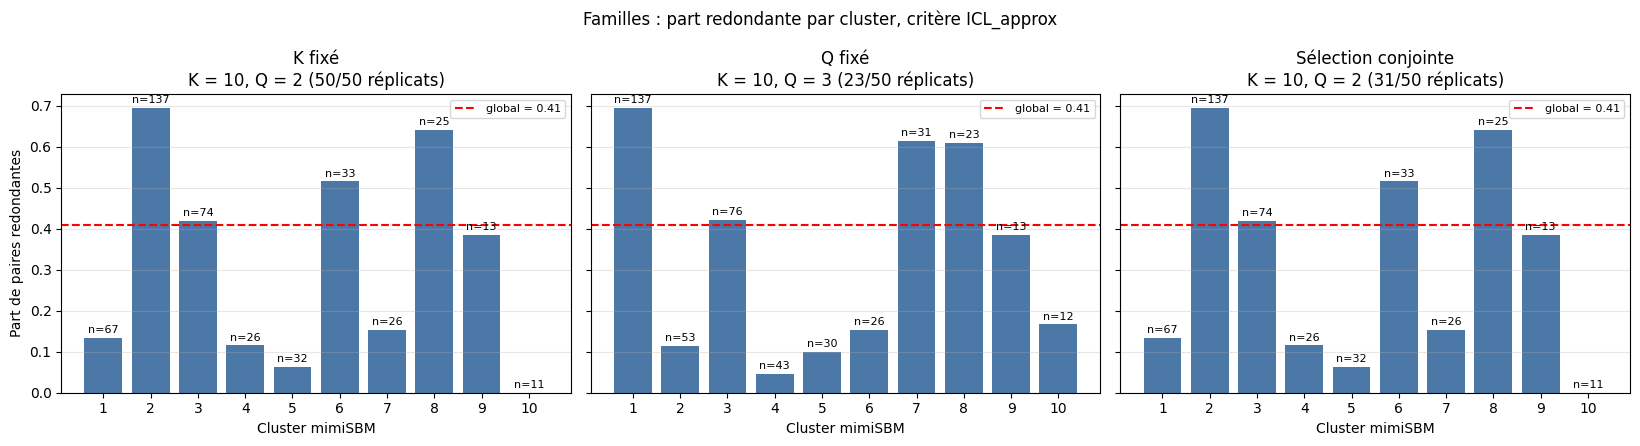

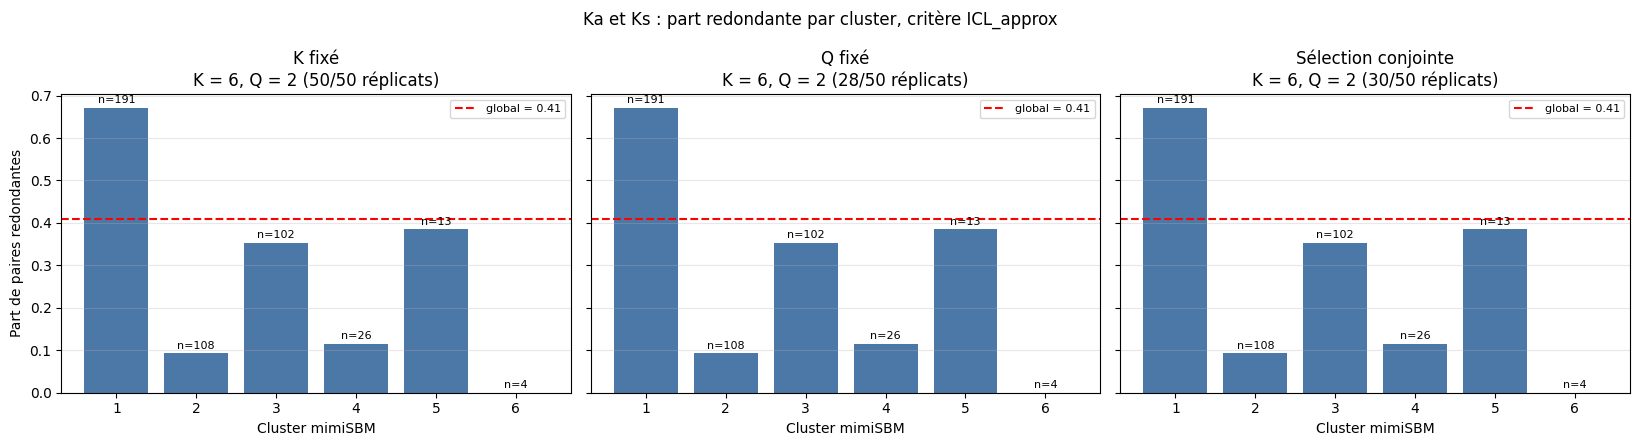

In [10]:
for jeu in ratios["jeu"].unique():
    fig, axes = plt.subplots(1, len(ORDRE_CAS), figsize=(5.5 * len(ORDRE_CAS), 4.5), sharey=True)
    for ax, cas in zip(np.atleast_1d(axes), ORDRE_CAS):
        t = ratios[(ratios["jeu"] == jeu) & (ratios["cas"] == cas) & (ratios["critere"] == CRITERE_FIGURE)]
        if t.empty:
            ax.set_axis_off()
            continue
        m = majo[(majo["jeu"] == jeu) & (majo["cas"] == cas) & (majo["critere"] == CRITERE_FIGURE)].iloc[0]
        barres = ax.bar(t["cluster"].astype(str), t["part_redondant"], color="#4C78A8")
        ax.bar_label(barres, labels=[f"n={n}" for n in t["n"]], fontsize=8, padding=2)
        glob = t["n_redondant"].sum() / t["n"].sum()
        ax.axhline(glob, color="red", ls="--", label=f"global = {glob:.2f}")
        ax.set(title=f"{cas}\nK = {m.K_majoritaire}, Q = {m.Q_associe} ({m.freq_K}/{m.n_simulations} réplicats)",
               xlabel="Cluster mimiSBM")
        ax.grid(axis="y", alpha=0.3)
        ax.legend(fontsize=8)
    np.atleast_1d(axes)[0].set_ylabel("Part de paires redondantes")
    fig.suptitle(f"{jeu} : part redondante par cluster, critère {CRITERE_FIGURE}")
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"ratio_{jeu.replace(' ', '_')}_{CRITERE_FIGURE}.png", dpi=150)
    plt.show()